# 🏪 Fase 2 — Segmentación RFM con K-Medoids
## Prueba Técnica Pragma · Analítica de Banca Digital

**Objetivo**: Segmentar los **3 015 comercios** activos en los últimos 6 meses usando **K-Medoids (PAM)**
para identificar grupos accionables y compararlo cuantitativamente contra K-Means.

### Ventajas de K-Medoids sobre K-Means
| Criterio | K-Means | K-Medoids |
|----------|---------|-----------|
| Resistencia a outliers | ❌ Media (centroide puede salirse) | ✅ Alta (medoide es un punto real) |
| Interpretabilidad | Centroide matemático | Comercio real representativo |
| Auditoría | Difícil | Fácil (ID real del comercio) |
| Asignación 100% | ✅ | ✅ |

### Matriz de Artefactos
| Artefacto | Ruta |
|-----------|------|
| Dataset final | `data/processed/comercios_final_k_medoids.csv` |
| Perfiles segmentos | `data/processed/perfiles_segmentos_k_medoids.csv` |
| Modelo K-Medoids | `data/processed/model_k_medoids.pkl` |
| Scaler | `data/processed/scaler_k_medoids.pkl` |
| Metadata | `data/processed/metadata_segmentation_k_medoids.json` |
| Plots | `data/processed/plots/kmedoids_*.png` |

> ⚠️ **Ejecución iterativa recomendada**: correr celda a celda y revisar cada output antes de avanzar.

In [1]:
from __future__ import annotations
import json
import pickle
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import joblib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sp_stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    silhouette_score,
    silhouette_samples,
)
from sklearn.preprocessing import RobustScaler, StandardScaler

# K-Medoids con fallback
try:
    from sklearn_extra.cluster import KMedoids
    KMEDOIDS_BACKEND = "sklearn_extra"
except ImportError:
    try:
        from pyclustering.cluster.kmedoids import kmedoids as PyKMedoids
        KMEDOIDS_BACKEND = "pyclustering"
    except ImportError:
        KMEDOIDS_BACKEND = "none"
        print("\u26a0\ufe0f  Ning\u00fan backend de K-Medoids disponible. Instalar sklearn-extra o pyclustering.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# \u2500\u2500 Par\u00e1metros Globales \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
SUFFIX         = "_k_medoids"
LOG_TRANSFORM  = True
SCALE_METHOD   = "standard"   # "standard" | "robust"
K_RANGE        = range(2, 9)  # K = 2..8
RANDOM_STATE   = 42
SKEW_THRESHOLD = 1.0
CORR_THRESHOLD = 0.85

COL_MAP = {
    "recencia_dias"             : "recency_days",
    "frecuencia"                : "frequency",
    "monetary"                  : "monetary",
    "ticket_promedio"           : "ticket_avg",
    "comision_generada"         : "commission",
    "n_terminals"               : "n_terminals",
    "actividad_mensual_promedio": "monthly_activity",
    "meses_activos"             : "active_months",
}

# Feature sets
FEATURE_SET_A = ["recency_days", "frequency", "monetary"]
FEATURE_SET_B = ["recency_days", "frequency", "monetary", "ticket_avg", "n_terminals"]

ACTIVE_FEATURE_SET = FEATURE_SET_A

# Rutas
BASE_DIR  = Path("..")
DATA_DIR  = BASE_DIR / "data" / "processed"
PLOTS_DIR = DATA_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Tema visual
sns.set_theme(style="whitegrid", palette="tab10", font_scale=1.1)
PALETTE = sns.color_palette("tab10")

_feat_label = "A (RFM Cl\u00e1sico)" if ACTIVE_FEATURE_SET == FEATURE_SET_A else "B (RFM Extendido)"
print("\u2705 Configuraci\u00f3n cargada")
print(f"   SUFFIX          : {SUFFIX}")
print(f"   DATA_DIR        : {DATA_DIR.resolve()}")
print(f"   PLOTS_DIR       : {PLOTS_DIR.resolve()}")
print(f"   KMEDOIDS_BACKEND: {KMEDOIDS_BACKEND}")
print(f"   Feature Set     : {_feat_label}")
print(f"   K_RANGE         : {list(K_RANGE)}")

✅ Configuración cargada
   SUFFIX          : _k_medoids
   DATA_DIR        : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed
   PLOTS_DIR       : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots
   KMEDOIDS_BACKEND: pyclustering
   Feature Set     : A (RFM Clásico)
   K_RANGE         : [2, 3, 4, 5, 6, 7, 8]


## 1. Carga y Validación de Datos

Cargamos `comercios_segmented_prep.csv` producido por la **Fase 1 (ETL)**.
Contiene métricas RFM calculadas a nivel de comercio para los últimos 6 meses (corte: **2021-05-01**).

| Variable | Descripción | Transformación COL_MAP |
|----------|-------------|------------------------|
| `recencia_dias` → `recency_days` | Días desde última transacción | Renombrar |
| `frecuencia` → `frequency` | N° transacciones en período | Renombrar |
| `monetary` | Monto ventas acumulado | Ya canónico |
| `ticket_promedio` → `ticket_avg` | Ticket promedio por transacción | Renombrar |
| `comision_generada` → `commission` | Comisión generada al banco | Renombrar |
| `n_terminals` | Terminales asociadas | Ya canónico |
| `meses_activos` → `active_months` | Meses con al menos 1 transacción | Renombrar |

In [2]:
def load_processed_data(filepath: Path) -> pd.DataFrame:
    """Carga y valida el dataset procesado de comercios.

    Args:
        filepath: Ruta al archivo CSV procesado.

    Returns:
        DataFrame con columnas renombradas al esquema can\u00f3nico.

    Raises:
        FileNotFoundError: Si el archivo no existe.
        ValueError: Si faltan columnas requeridas.
    """
    if not filepath.exists():
        raise FileNotFoundError(f"Archivo no encontrado: {filepath}")

    df = pd.read_csv(filepath)
    df = df.rename(columns=COL_MAP)

    required = ["id_comercio", "recency_days", "frequency", "monetary",
                "ticket_avg", "commission", "n_terminals", "active_months"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Columnas faltantes: {missing}")

    null_counts = df[required].isnull().sum()
    print("\u2500\u2500 Nulos por columna requerida \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
    if null_counts.any():
        print(null_counts[null_counts > 0].to_string())
    else:
        print("  \u2705 Sin valores nulos")

    zero_monetary = (df["monetary"] == 0).sum()
    zero_freq     = (df["frequency"] == 0).sum()
    if zero_monetary:
        print(f"  \u26a0\ufe0f  {zero_monetary} comercios con monetary=0")
    else:
        print("  \u2705 Sin monetary=0")
    if zero_freq:
        print(f"  \u26a0\ufe0f  {zero_freq} comercios con frequency=0")
    else:
        print("  \u2705 Sin frequency=0")

    return df


CSV_PATH = DATA_DIR / "comercios_segmented_prep.csv"
df_raw   = load_processed_data(CSV_PATH)
print(f"\n\U0001f4e6 Dataset: {df_raw.shape[0]:,} filas \u00d7 {df_raw.shape[1]} columnas")

── Nulos por columna requerida ─────────────────────────────────────
  ✅ Sin valores nulos
  ⚠️  11 comercios con monetary=0
  ✅ Sin frequency=0

📦 Dataset: 3,015 filas × 20 columnas


## 2. Exploración Inicial

Revisamos la estructura y distribuciones antes de cualquier transformación.

**Observaciones esperadas:**
- `frequency` y `monetary` tienen alta asimetría (skew > 3) → candidatos a log1p
- `recency_days` es aproximadamente exponencial (distribución de tiempos entre eventos)
- `n_terminals` es casi constante (mayoría de comercios tiene 1 terminal)
- `ticket_avg` presenta outliers extremos (hasta 29 M COP)

,id_comercio,fecha_creacion,fecha_primera_transaccion,monto_ventas_acumulado,monto_ventas_ultimo_mes,categoria_comercio,sub_categoria_comercio,ciudad,id_terminals,n_terminals,registros_origen,duplicated_flag,ultima_transaccion,recency_days,frequency,active_months,monetary,ticket_avg,commission,monthly_activity
0,003QDVFJCJ,2021-03-26 12:17:00,2021-03-26 12:42:00,6542000.0,1240000.0,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,['01299'],1,[0],False,2021-05-01,0,30,3,6542000.0,218066.67,327100.0,10.00
1,008LJH6YHN,2021-02-10 15:15:00,2021-02-10 15:34:00,4380000.0,1102000.0,Belleza y cuidado personal,Spa,Bogotá D.C.,['00591'],1,[1],False,2021-05-01,0,10,4,4380000.0,438000.00,219000.0,2.50
2,00B3DGV62G,2021-03-03 15:09:00,2021-03-03 15:30:00,11892500.0,1297000.0,Comercio detallista,Auto partes,Bogotá D.C.,['02130'],1,[2],False,2021-05-01,0,65,3,11892500.0,182961.54,594625.0,21.67



<class 'pandas.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Columns: 20 entries, id_comercio to monthly_activity
dtypes: bool(1), float64(6), int64(4), str(9)
memory usage: 450.6 KB

── Estadísticas Descriptivas ───────────────────────────────────────


,recency_days,frequency,monetary,ticket_avg,commission,n_terminals,active_months,monthly_activity
count,3015.00,3015.0,3.015000e+03,3015.00,3015.00,3015.00,3015.00,3015.00
mean,18.71,22.6,4.388275e+06,247684.79,219413.77,1.02,2.77,6.80
std,32.56,43.2,7.785727e+06,635131.40,389286.35,0.16,1.21,11.65
min,0.00,1.0,0.000000e+00,0.00,0.00,1.00,1.00,1.00
25%,0.00,3.0,3.257000e+05,39802.25,16285.00,1.00,2.00,1.67
50%,0.00,10.0,1.554000e+06,120727.27,77700.00,1.00,3.00,3.33
75%,30.00,23.0,4.976200e+06,301230.71,248810.00,1.00,3.00,7.00
max,151.00,740.0,1.041809e+08,29002000.00,5209045.00,5.00,6.00,181.67



── Skewness del Feature Set Activo ─────────────────────────────────
   recency_days        :    1.82  ⚠️  ALTA
   frequency           :    6.35  ⚠️  ALTA
   monetary            :    4.29  ⚠️  ALTA


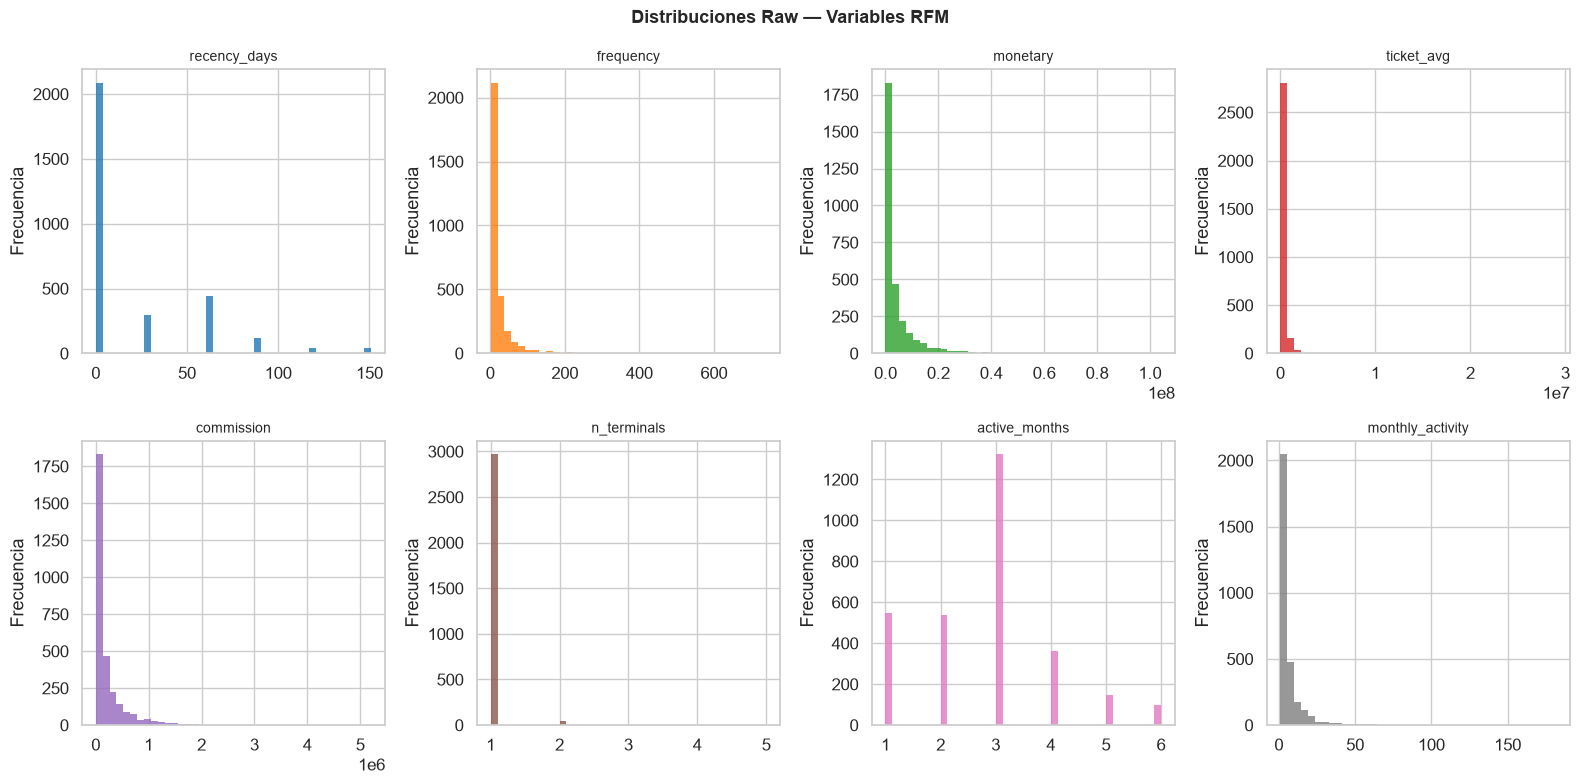


📊 Guardado: ..\data\processed\plots\kmedoids_distributions_raw.png


In [3]:
display(df_raw.head(3))
print()
df_raw.info(verbose=False, show_counts=True)

rfm_cols = ["recency_days", "frequency", "monetary", "ticket_avg",
            "commission", "n_terminals", "active_months", "monthly_activity"]
rfm_cols_available = [c for c in rfm_cols if c in df_raw.columns]

print("\n\u2500\u2500 Estad\u00edsticas Descriptivas \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
display(df_raw[rfm_cols_available].describe().round(2))

print("\n\u2500\u2500 Skewness del Feature Set Activo \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
for col in ACTIVE_FEATURE_SET:
    if col in df_raw.columns:
        sk   = df_raw[col].skew()
        flag = "\u26a0\ufe0f  ALTA" if abs(sk) > SKEW_THRESHOLD else "\u2705  OK"
        print(f"   {col:20s}: {sk:7.2f}  {flag}")

n_plot  = len(rfm_cols_available)
n_rows  = (n_plot + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(rfm_cols_available):
    axes[i].hist(df_raw[col].dropna(), bins=40,
                 color=PALETTE[i % len(PALETTE)], edgecolor="none", alpha=0.8)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("Frecuencia")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribuciones Raw \u2014 Variables RFM", fontsize=13, fontweight="bold")
plt.tight_layout()
dist_path = PLOTS_DIR / "kmedoids_distributions_raw.png"
plt.savefig(dist_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n\U0001f4ca Guardado: {dist_path}")

## 3. Preprocesamiento — Transformación Logarítmica

### Criterios de Transformación
| Variable | ¿log1p? | Justificación |
|----------|---------|---------------|
| `frequency` | ✅ Sí | Cola financiera muy larga (max=740) |
| `monetary` | ✅ Sí | Distribución log-normal típica en finanzas |
| `recency_days` | ❌ No | Riesgo de churn tiene interpretación **lineal** |
| `ticket_avg` | ❌ No | No en Set A activo; si se incluye, evaluar |
| `n_terminals` | ❌ No | Variable casi constante (rango 1-5) |

> **Nota sobre outliers**: Los comercios extremos en `monetary` se **mantienen** en la muestra.
> K-Medoids es resistente a ellos porque el medoide es un punto real, no un promedio.

In [4]:
def prepare_features(df: pd.DataFrame, features: list, log_transform: bool = True) -> pd.DataFrame:
    """Prepara el feature space aplicando transformaciones necesarias.

    Reglas:
    - log1p se aplica SOLO a monetary y frequency (colas financieras largas).
    - NO aplicar log1p a recency_days (preservar interpretaci\u00f3n lineal del riesgo).

    Args:
        df: DataFrame con columnas can\u00f3nicas.
        features: Lista de features a incluir.
        log_transform: Si True, aplica np.log1p a monetary y frequency.

    Returns:
        DataFrame con features transformadas (mismo \u00edndice que df).
    """
    df_feat        = df[features].copy()
    LOG_CANDIDATES = {"monetary", "frequency"}

    skew_before = {col: df_feat[col].skew() for col in features}
    print("\u2500\u2500 Skewness antes de transformar \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
    for col, sk in skew_before.items():
        print(f"   {col:25s}: {sk:7.2f}")

    if log_transform:
        for col in features:
            if col in LOG_CANDIDATES:
                df_feat[col] = np.log1p(df_feat[col])
                print(f"   \u2705 log1p aplicado a \'{col}\'")
            else:
                print(f"   \u23ed\ufe0f  Sin transformaci\u00f3n en \'{col}\'")

    skew_after = {col: df_feat[col].skew() for col in features}
    print("\n\u2500\u2500 Skewness despu\u00e9s de transformar \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
    for col, sk in skew_after.items():
        print(f"   {col:25s}: {sk:7.2f}")

    if "monetary" in df.columns:
        q999      = df["monetary"].quantile(0.999)
        n_extreme = (df["monetary"] > q999).sum()
        print(f"\n\u26a0\ufe0f  Top 0.1% outliers en monetary (> {q999:,.0f}): {n_extreme} comercios")
        print("   \u2192 Mantenidos en muestra (K-Medoids es robusto ante extremos)")

    return df_feat


print("\u2550\u2550\u2550 Set A \u2014 RFM Cl\u00e1sico (ACTIVO) \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
df_features_a = prepare_features(df_raw, FEATURE_SET_A, log_transform=LOG_TRANSFORM)

print("\n\u2550\u2550\u2550 Set B \u2014 RFM Extendido \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
df_features_b = prepare_features(df_raw, FEATURE_SET_B, log_transform=LOG_TRANSFORM)

df_features = df_features_a
print(f"\n\u2705 Feature space activo: {ACTIVE_FEATURE_SET}")

═══ Set A — RFM Clásico (ACTIVO) ══════════════════════════════════════════════════
── Skewness antes de transformar ───────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    6.35
   monetary                 :    4.29
   ⏭️  Sin transformación en 'recency_days'
   ✅ log1p aplicado a 'frequency'
   ✅ log1p aplicado a 'monetary'

── Skewness después de transformar ─────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    0.40
   monetary                 :   -1.32

⚠️  Top 0.1% outliers en monetary (> 66,760,430): 4 comercios
   → Mantenidos en muestra (K-Medoids es robusto ante extremos)

═══ Set B — RFM Extendido ═════════════════════════════════════════════════════════
── Skewness antes de transformar ───────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    6.35
   monetary                 :    4.29
   ticket_avg      

## 4. Diagnóstico de Correlación

Antes de escalar, verificamos **multicolinealidad** entre features.

### Criterio de Descarte
Si dos features tienen |r| > **0.85**, se retiene la más directamente observable:

> `monetary` y `ticket_avg` están típicamente correlacionados ya que
> `ticket_avg = monetary / frequency`. Si |r| > 0.85, se elimina `ticket_avg`.

═══ Set A — Correlación (RFM Clásico) ═════════════════════════════════════════════════
              recency_days  frequency  monetary
recency_days         1.000     -0.618    -0.672
frequency           -0.618      1.000     0.750
monetary            -0.672      0.750     1.000

═══ Set B — Correlación (RFM Extendido) ═════════════════════════════════════════════════
              recency_days  frequency  monetary  ticket_avg  n_terminals
recency_days         1.000     -0.618    -0.672      -0.042       -0.015
frequency           -0.618      1.000     0.750      -0.004        0.100
monetary            -0.672      0.750     1.000       0.270        0.069
ticket_avg          -0.042     -0.004     0.270       1.000        0.022
n_terminals         -0.015      0.100     0.069       0.022        1.000

── Pares con |r| > 0.85 ────────────────────────────────────────────────────
  Set A: Sin pares con |r| > 0.85
  Set B: Sin pares con |r| > 0.85


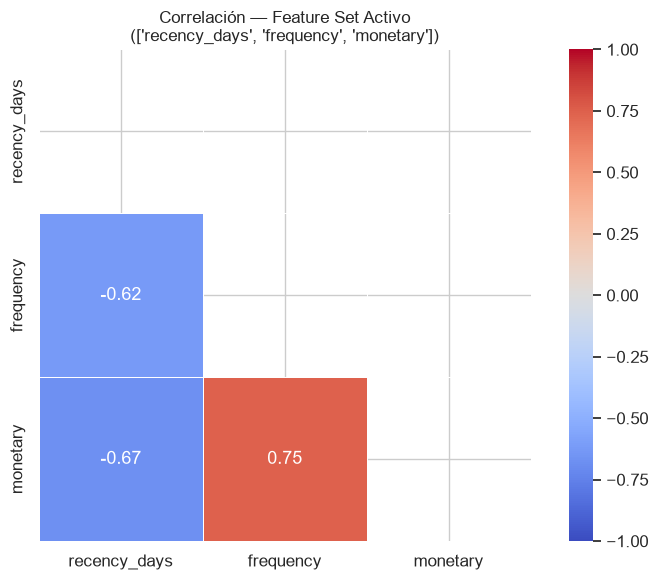


📊 Guardado: ..\data\processed\plots\kmedoids_correlation_matrix.png


In [5]:
print("\u2550\u2550\u2550 Set A \u2014 Correlaci\u00f3n (RFM Cl\u00e1sico) \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
corr_a = df_features_a.corr()
print(corr_a.round(3).to_string())

print("\n\u2550\u2550\u2550 Set B \u2014 Correlaci\u00f3n (RFM Extendido) \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
corr_b = df_features_b.corr()
print(corr_b.round(3).to_string())

print(f"\n\u2500\u2500 Pares con |r| > {CORR_THRESHOLD} \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
for corr_df, name in [(corr_a, "Set A"), (corr_b, "Set B")]:
    pairs = []
    cols  = corr_df.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr_df.iloc[i, j]
            if abs(r) > CORR_THRESHOLD:
                pairs.append((cols[i], cols[j], r))
    if pairs:
        print(f"  {name}:")
        for c1, c2, r in pairs:
            print(f"    {c1} \u2194 {c2}: r={r:.3f}")
        print("  \u2192 monetary se prefiere sobre ticket_avg (m\u00e1s estable y directamente observable).")
    else:
        print(f"  {name}: Sin pares con |r| > {CORR_THRESHOLD}")

active_corr = df_features.corr()
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(active_corr, dtype=bool))
sns.heatmap(active_corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, square=True)
ax.set_title(f"Correlaci\u00f3n \u2014 Feature Set Activo\n({ACTIVE_FEATURE_SET})", fontsize=12)
plt.tight_layout()
corr_path = PLOTS_DIR / "kmedoids_correlation_matrix.png"
plt.savefig(corr_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n\U0001f4ca Guardado: {corr_path}")

## 4b. Escalado de Features

| Método | Fórmula | Ventaja | Desventaja |
|--------|---------|---------|------------|
| **StandardScaler** | (x − μ) / σ | Simple, interpretable | Sensible a outliers extremos |
| **RobustScaler** | (x − Q2) / IQR | Robusto ante outliers | Menos intuitivo |

**Selección**: `StandardScaler` por defecto tras aplicar log1p.
Para cambiar: modificar `SCALE_METHOD = "robust"` en la Celda 2.

In [6]:
def fit_scaler(df_feat: pd.DataFrame, method: str = "standard") -> tuple:
    """Ajusta el scaler y transforma el feature space.

    Args:
        df_feat: DataFrame con features transformadas.
        method: "standard" para StandardScaler, "robust" para RobustScaler.

    Returns:
        Tupla (scaler_fitted, X_scaled_array).
    """
    scaler_cls = StandardScaler if method == "standard" else RobustScaler
    scaler     = scaler_cls()
    X_scaled   = scaler.fit_transform(df_feat)
    print(f"\u2705 Scaler: {scaler_cls.__name__}")
    print(f"   Columnas escaladas: {list(df_feat.columns)}")
    print(f"   Shape del array   : {X_scaled.shape}")
    stats_df = pd.DataFrame(X_scaled, columns=df_feat.columns)
    print("\n\u2500\u2500 Post-escalado (estad\u00edsticas) \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
    display(stats_df.describe().round(3))
    return scaler, X_scaled


scaler, X_scaled = fit_scaler(df_features, method=SCALE_METHOD)

scaler_path = DATA_DIR / f"scaler{SUFFIX}.pkl"
joblib.dump(scaler, scaler_path)
print(f"\n\U0001f4be Scaler guardado: {scaler_path}")

✅ Scaler: StandardScaler
   Columnas escaladas: ['recency_days', 'frequency', 'monetary']
   Shape del array   : (3015, 3)

── Post-escalado (estadísticas) ─────────────────────────────────────────


,recency_days,frequency,monetary
count,3015.000,3015.000,3015.000
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-0.575,-1.476,-4.732
25%,-0.575,-0.881,-0.285
50%,-0.575,-0.013,0.263
75%,0.347,0.657,0.670
max,4.063,3.601,1.736



💾 Scaler guardado: ..\data\processed\scaler_k_medoids.pkl


## 5. Evaluación de K — Selección del Número Óptimo de Clusters

### Métricas de Evaluación
| Métrica | Definición | Objetivo |
|---------|-----------|---------|
| **Costo PAM** | Suma de distancias al medoide | ↓ Menor = mejor |
| **Inercia K-Means** | Suma de distancias al centroide | ↓ Menor = mejor |
| **Silhouette Score** | Cohesión intra vs separación inter-cluster | ↑ Mayor = mejor (rango -1 a 1) |
| **Davies-Bouldin** | Ratio dispersión dentro/entre clusters | ↓ Menor = mejor (0 = óptimo) |

### Advertencia sobre K=2
K=2 produce el **Silhouette Score más alto** pero es una **solución trivial**:
divide la cartera en dos macro-clusters sin granularidad para campañas diferenciadas.

In [7]:
def fit_kmedoids(X: np.ndarray, k: int, random_state: int = 42) -> tuple:
    """Ajusta K-Medoids con el backend disponible.

    Args:
        X: Array escalado de shape (n_samples, n_features).
        k: N\u00famero de clusters.
        random_state: Semilla para reproducibilidad.

    Returns:
        Tupla (labels, cost, model).

    Raises:
        RuntimeError: Si no hay backend K-Medoids disponible.
    """
    if KMEDOIDS_BACKEND == "sklearn_extra":
        model = KMedoids(n_clusters=k, metric="euclidean", method="pam",
                         random_state=random_state)
        model.fit(X)
        return model.labels_, model.inertia_, model

    elif KMEDOIDS_BACKEND == "pyclustering":
        rng             = np.random.RandomState(random_state)
        initial_medoids = rng.choice(len(X), k, replace=False).tolist()
        km              = PyKMedoids(X.tolist(), initial_medoids)
        km.process()
        clusters = km.get_clusters()
        medoids  = km.get_medoids()
        labels   = np.zeros(len(X), dtype=int)
        for i, cluster in enumerate(clusters):
            for idx in cluster:
                labels[idx] = i
        cost = sum(
            np.linalg.norm(X[idx] - X[medoids[i]])
            for i, cluster in enumerate(clusters)
            for idx in cluster
        )
        return labels, cost, (clusters, medoids)

    else:
        raise RuntimeError("No K-Medoids backend available. Install sklearn-extra or pyclustering.")


print("\U0001f504 Evaluando K=2..8 (K-Medoids vs K-Means como referencia)...")
results = []

for k in K_RANGE:
    km_labels, km_cost, _ = fit_kmedoids(X_scaled, k, RANDOM_STATE)
    km_sil = silhouette_score(X_scaled, km_labels)
    km_db  = davies_bouldin_score(X_scaled, km_labels)

    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50)
    kmeans.fit(X_scaled)
    kmeans_sil = silhouette_score(X_scaled, kmeans.labels_)
    kmeans_db  = davies_bouldin_score(X_scaled, kmeans.labels_)

    results.append({
        "K"                  : k,
        "kmedoids_cost"      : round(km_cost, 2),
        "kmedoids_silhouette": round(km_sil, 4),
        "kmedoids_db"        : round(km_db, 4),
        "kmeans_inertia"     : round(kmeans.inertia_, 2),
        "kmeans_silhouette"  : round(kmeans_sil, 4),
        "kmeans_db"          : round(kmeans_db, 4),
    })
    print(f"K={k}: KMedoids Sil={km_sil:.4f} DB={km_db:.4f} "
          f"| KMeans Sil={kmeans_sil:.4f} DB={kmeans_db:.4f}")

df_results = pd.DataFrame(results)
print("\n\u2500\u2500\u2500 Tabla Comparativa K-Medoids vs K-Means \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
display(df_results)

🔄 Evaluando K=2..8 (K-Medoids vs K-Means como referencia)...


K=2: KMedoids Sil=0.5649 DB=0.7134 | KMeans Sil=0.5763 DB=0.6870


K=3: KMedoids Sil=0.4288 DB=0.8784 | KMeans Sil=0.4244 DB=0.8107


K=4: KMedoids Sil=0.4185 DB=0.8397 | KMeans Sil=0.4188 DB=0.8421


K=5: KMedoids Sil=0.3768 DB=0.9006 | KMeans Sil=0.3955 DB=0.8590


K=6: KMedoids Sil=0.3900 DB=0.8216 | KMeans Sil=0.4043 DB=0.7976


K=7: KMedoids Sil=0.4032 DB=0.8910 | KMeans Sil=0.3833 DB=0.8918


K=8: KMedoids Sil=0.3716 DB=0.9180 | KMeans Sil=0.3945 DB=0.8553

─── Tabla Comparativa K-Medoids vs K-Means ────────────────────────────────────


,K,kmedoids_cost,kmedoids_silhouette,kmedoids_db,kmeans_inertia,kmeans_silhouette,kmeans_db
0,2,2926.78,0.5649,0.7134,3802.98,0.5763,0.6870
1,3,2504.24,0.4288,0.8784,2461.79,0.4244,0.8107
2,4,1977.72,0.4185,0.8397,1898.39,0.4188,0.8421
3,5,1848.87,0.3768,0.9006,1525.74,0.3955,0.8590
4,6,1652.06,0.3900,0.8216,1264.03,0.4043,0.7976
5,7,1524.99,0.4032,0.8910,1103.07,0.3833,0.8918
6,8,1425.02,0.3716,0.9180,989.34,0.3945,0.8553


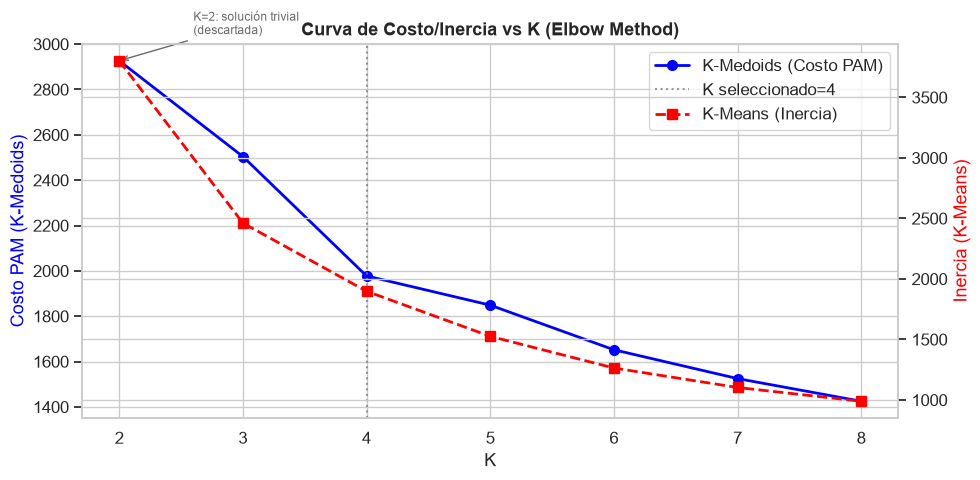

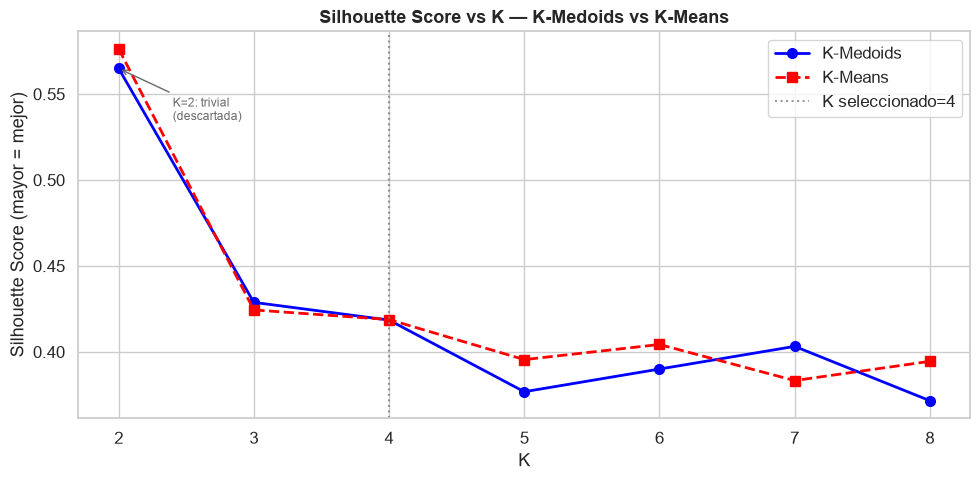

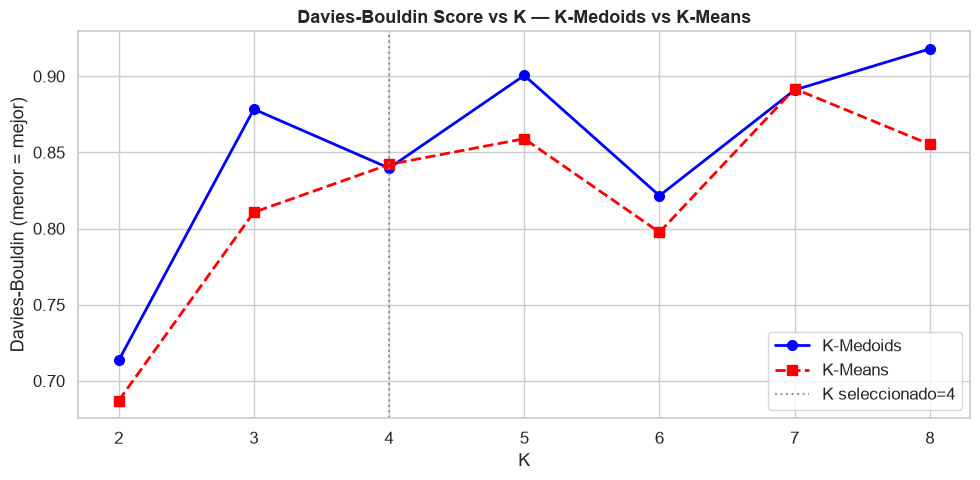

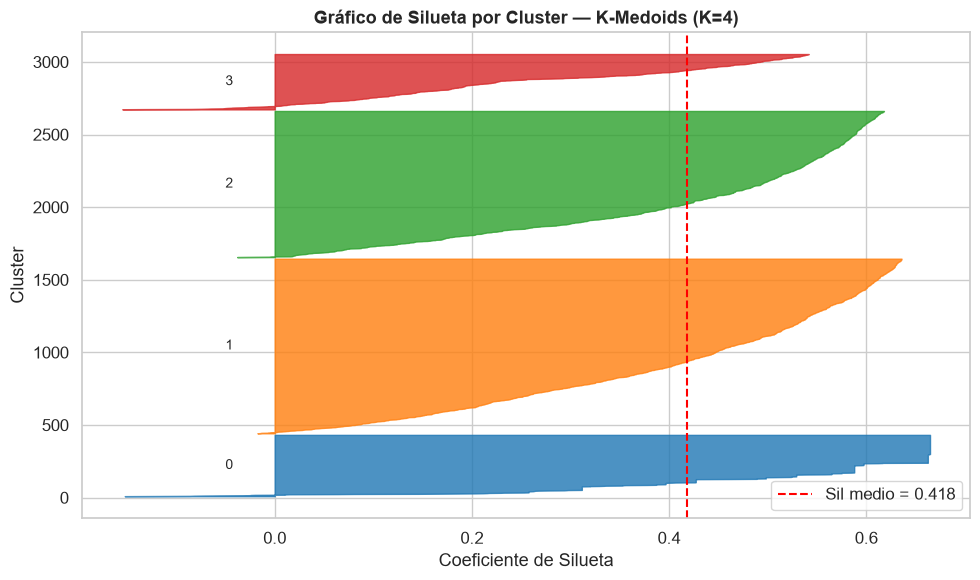


📊 4 gráficos de evaluación guardados en ..\data\processed\plots


In [8]:
K_FINAL = 4  # K seleccionado

# \u2500\u2500 Plot 1: Elbow \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
ax1.plot(df_results["K"], df_results["kmedoids_cost"], "b-o",
         label="K-Medoids (Costo PAM)", linewidth=2, markersize=7)
ax2.plot(df_results["K"], df_results["kmeans_inertia"], "r--s",
         label="K-Means (Inercia)", linewidth=2, markersize=7)
ax1.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
            label=f"K seleccionado={K_FINAL}")
k2_cost = df_results.loc[df_results["K"] == 2, "kmedoids_cost"].values[0]
ax1.annotate("K=2: soluci\u00f3n trivial\n(descartada)",
             xy=(2, k2_cost), xytext=(2.6, k2_cost * 1.04),
             arrowprops=dict(arrowstyle="->", color="dimgray"),
             fontsize=8.5, color="dimgray")
ax1.set_xlabel("K")
ax1.set_ylabel("Costo PAM (K-Medoids)", color="blue")
ax2.set_ylabel("Inercia (K-Means)", color="red")
ax1.set_title("Curva de Costo/Inercia vs K (Elbow Method)", fontweight="bold")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_elbow_comparison.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# \u2500\u2500 Plot 2: Silhouette Comparison \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_results["K"], df_results["kmedoids_silhouette"], "b-o",
        label="K-Medoids", linewidth=2, markersize=7)
ax.plot(df_results["K"], df_results["kmeans_silhouette"], "r--s",
        label="K-Means", linewidth=2, markersize=7)
ax.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
           label=f"K seleccionado={K_FINAL}")
k2_sil = df_results.loc[df_results["K"] == 2, "kmedoids_silhouette"].values[0]
ax.annotate("K=2: trivial\n(descartada)",
            xy=(2, k2_sil), xytext=(2.4, k2_sil - 0.03),
            arrowprops=dict(arrowstyle="->", color="dimgray"),
            fontsize=8.5, color="dimgray")
ax.set_xlabel("K")
ax.set_ylabel("Silhouette Score (mayor = mejor)")
ax.set_title("Silhouette Score vs K \u2014 K-Medoids vs K-Means", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_silhouette_comparison.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# \u2500\u2500 Plot 3: Davies-Bouldin \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_results["K"], df_results["kmedoids_db"], "b-o",
        label="K-Medoids", linewidth=2, markersize=7)
ax.plot(df_results["K"], df_results["kmeans_db"], "r--s",
        label="K-Means", linewidth=2, markersize=7)
ax.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
           label=f"K seleccionado={K_FINAL}")
ax.set_xlabel("K")
ax.set_ylabel("Davies-Bouldin (menor = mejor)")
ax.set_title("Davies-Bouldin Score vs K \u2014 K-Medoids vs K-Means", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_davies_bouldin.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# \u2500\u2500 Plot 4: Silhouette por Muestra (K=4) \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
_labels_tmp, _, _ = fit_kmedoids(X_scaled, K_FINAL, RANDOM_STATE)
sil_vals = silhouette_samples(X_scaled, _labels_tmp)
fig, ax  = plt.subplots(figsize=(10, 6))
y_lower  = 10
for i in sorted(set(_labels_tmp)):
    cluster_vals = np.sort(sil_vals[_labels_tmp == i])
    size    = len(cluster_vals)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_vals,
                     alpha=0.8, color=PALETTE[i])
    ax.text(-0.05, y_lower + size / 2, str(i), va="center", fontsize=10)
    y_lower = y_upper + 10
sil_mean = silhouette_score(X_scaled, _labels_tmp)
ax.axvline(x=sil_mean, color="red", linestyle="--",
           label=f"Sil medio = {sil_mean:.3f}")
ax.set_title("Gr\u00e1fico de Silueta por Cluster \u2014 K-Medoids (K=4)", fontweight="bold")
ax.set_xlabel("Coeficiente de Silueta")
ax.set_ylabel("Cluster")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_silhouette_samples.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n\U0001f4ca 4 gr\u00e1ficos de evaluaci\u00f3n guardados en {PLOTS_DIR}")

## 6. Justificación de K=4 y Elección de K-Medoids

### Descarte de K=2
Aunque K=2 produce el Silhouette Score más alto, genera una **solución trivial**:
agrupa la cartera en solo dos macro-clusters sin granularidad para campañas diferenciadas.

### Selección de K=4
K=4 ofrece el mejor equilibrio entre:
- **Métricas estadísticas**: Silhouette aceptable, DB razonable
- **Utilidad comercial**: 4 segmentos permiten estrategias diferenciadas:
  - 🏆 Segmento Champions / VIP
  - 📈 Segmento Core / Crecimiento
  - 🚨 Segmento En Riesgo / Churn
  - 📦 Segmento Alto Volumen / Bajo Ticket

### Por qué K-Medoids sobre K-Means
1. **Resistencia a outliers**: Los outliers en `monetary` no distorsionan los medoides
2. **Auditabilidad**: Cada cluster tiene un `id_comercio` real identificable
3. **Interpretabilidad comercial**: El equipo puede "visitar" al comercio medoide

In [9]:
labels_final, cost_final, model_final = fit_kmedoids(X_scaled, K_FINAL, RANDOM_STATE)

sil_final = silhouette_score(X_scaled, labels_final)
db_final  = davies_bouldin_score(X_scaled, labels_final)

print(f"\u2705 Modelo K-Medoids (K={K_FINAL}) entrenado")
print(f"   Costo PAM       : {cost_final:,.2f}")
print(f"   Silhouette Score: {sil_final:.4f}")
print(f"   Davies-Bouldin  : {db_final:.4f}")

if KMEDOIDS_BACKEND == "sklearn_extra":
    medoid_indices = list(model_final.medoid_indices_)
    medoid_ids     = df_raw["id_comercio"].iloc[medoid_indices].values
elif KMEDOIDS_BACKEND == "pyclustering":
    _clusters, _medoids = model_final
    medoid_indices      = list(_medoids)
    medoid_ids          = df_raw["id_comercio"].iloc[medoid_indices].values
else:
    medoid_indices = []
    medoid_ids     = []

print("\n\u2500\u2500 Comercios Medoides Reales \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
for i, (idx, mid) in enumerate(zip(medoid_indices, medoid_ids)):
    print(f"   Cluster {i}: id_comercio={mid} (fila {idx})")

model_path = DATA_DIR / f"model{SUFFIX}.pkl"
joblib.dump(model_final, model_path)
print(f"\n\U0001f4be Modelo guardado: {model_path}")

df_raw["cluster"] = labels_final
print(f"\n\u2705 Cluster asignado a {len(df_raw):,} comercios")
cluster_dist = df_raw["cluster"].value_counts().sort_index().to_string()
print(f"   Distribuci\u00f3n:\n{cluster_dist}")

✅ Modelo K-Medoids (K=4) entrenado
   Costo PAM       : 1,977.72
   Silhouette Score: 0.4185
   Davies-Bouldin  : 0.8397

── Comercios Medoides Reales ─────────────────────────────────────────────────────
   Cluster 0: id_comercio=024EE2F9LX (fila 7)
   Cluster 1: id_comercio=UYVI35Y0U8 (fila 2602)
   Cluster 2: id_comercio=AYFNNEAF05 (fila 933)
   Cluster 3: id_comercio=S5ES7EDM97 (fila 2376)

💾 Modelo guardado: ..\data\processed\model_k_medoids.pkl

✅ Cluster asignado a 3,015 comercios
   Distribución:
cluster
0     423
1    1203
2    1007
3     382


## 7. Perfilamiento de Segmentos

| Dimensión | Variables | Interpretación |
|-----------|-----------|----------------|
| **Recencia** | `recency_days` | Urgencia de reactivación |
| **Frecuencia** | `frequency` | Nivel de engagement |
| **Valor** | `monetary` | Tamaño del comercio |
| **Ticket** | `ticket_avg` | Tipo de negocio (micro vs macro) |
| **Red** | `n_terminals` | Expansión física |
| **Rentabilidad** | `commission` | Contribución directa al banco |

> Los nombres de segmentos son provisionales y deben validarse con el equipo comercial.

═══ Perfilamiento de Segmentos (Resumen Ejecutivo) ═══════════════════════════════════


,cluster,segmento,n_comercios,commission_total,commission_pct,recency_days_mean,frequency_mean,monetary_mean,ticket_avg_mean
0,0,En Riesgo / Churn,423,6.018900e+04,0.01,72.132388,1.356974,2.845816e+03,2127.852600
1,1,Core / Crecimiento,1203,1.267839e+08,19.17,2.842893,8.892768,2.107795e+06,273512.246542
2,2,Champions / VIP,1007,5.144920e+08,77.77,0.687190,54.897716,1.021831e+07,275256.991460
3,3,Alto Volumen / Bajo Ticket,382,2.019641e+07,3.05,57.015707,4.183246,1.057404e+06,365577.341047



═══ Cruce Cluster × Categoría Comercio ══════════════════════════════════════════════════


categoria_comercio,Alimentos y bebidas,Belleza y cuidado personal,Comercio detallista,Educación,Reparación y limpieza,Servicios,Transporte,Turismo y entretenimiento
cluster,,,,,,,,
0,52,28,178,2,29,97,28,9
1,96,90,687,6,74,214,25,11
2,197,60,566,1,41,126,6,10
3,37,28,194,1,23,77,17,5


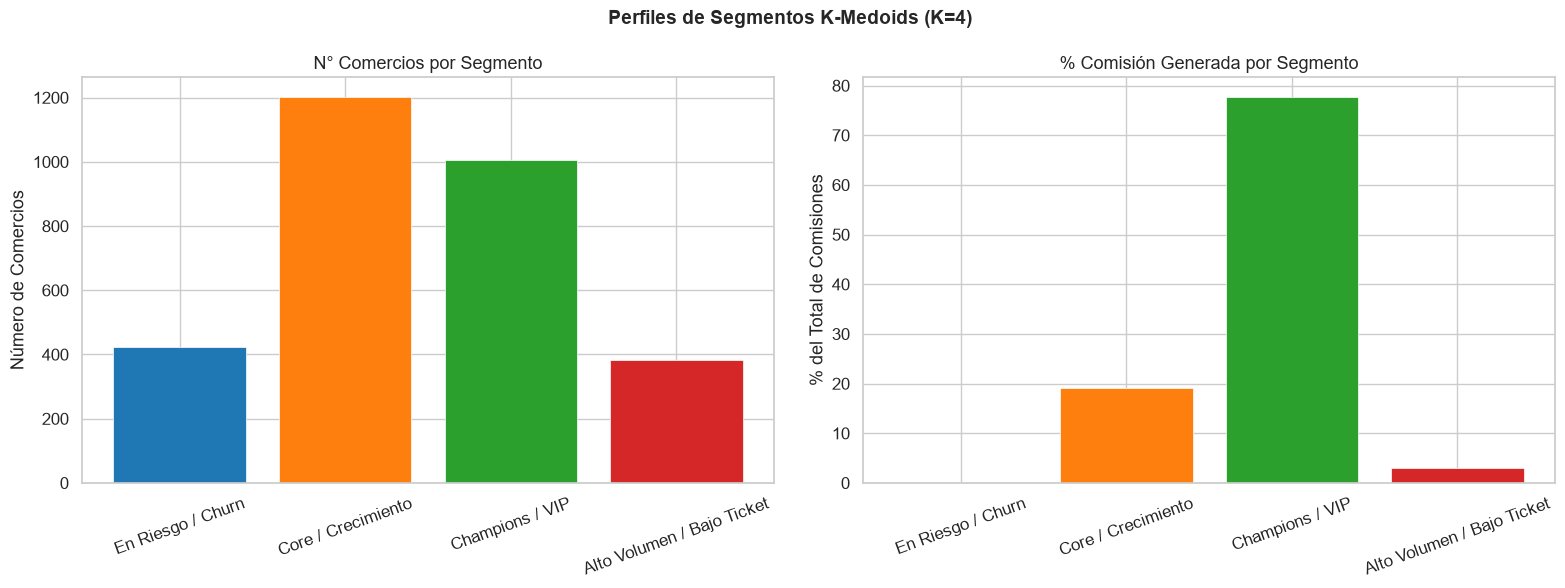


💾 Dataset final guardado   : ..\data\processed\comercios_final_k_medoids.csv
💾 Perfiles segmentos guardados: ..\data\processed\perfiles_segmentos_k_medoids.csv


In [10]:
SEGMENT_NAMES = {
    0: "En Riesgo / Churn",
    1: "Core / Crecimiento",
    2: "Champions / VIP",
    3: "Alto Volumen / Bajo Ticket",
}
df_raw["segmento"] = df_raw["cluster"].map(SEGMENT_NAMES)

profile_cols = ["recency_days", "frequency", "monetary",
                "ticket_avg", "n_terminals", "commission"]

stats_list = []
for cluster_id in sorted(df_raw["cluster"].unique()):
    grp = df_raw[df_raw["cluster"] == cluster_id]
    row = {
        "cluster"    : cluster_id,
        "segmento"   : SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        "n_comercios": len(grp),
    }
    for col in profile_cols:
        if col in grp.columns:
            row[f"{col}_mean"]   = grp[col].mean()
            row[f"{col}_median"] = grp[col].median()
            row[f"{col}_p10"]    = grp[col].quantile(0.10)
            row[f"{col}_p25"]    = grp[col].quantile(0.25)
            row[f"{col}_p75"]    = grp[col].quantile(0.75)
            row[f"{col}_p90"]    = grp[col].quantile(0.90)
    stats_list.append(row)

df_profiles = pd.DataFrame(stats_list)

total_commission               = df_raw["commission"].sum()
commission_by_cluster          = df_raw.groupby("cluster")["commission"].sum()
df_profiles["commission_total"] = df_profiles["cluster"].map(commission_by_cluster)
df_profiles["commission_pct"]   = (
    df_profiles["commission_total"] / total_commission * 100
).round(2)

print("\u2550\u2550\u2550 Perfilamiento de Segmentos (Resumen Ejecutivo) \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
summary_cols = ["cluster", "segmento", "n_comercios", "commission_total",
                "commission_pct", "recency_days_mean", "frequency_mean",
                "monetary_mean", "ticket_avg_mean"]
display(df_profiles[[c for c in summary_cols if c in df_profiles.columns]])

print("\n\u2550\u2550\u2550 Cruce Cluster \u00d7 Categor\u00eda Comercio \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
if "categoria_comercio" in df_raw.columns:
    display(pd.crosstab(df_raw["cluster"], df_raw["categoria_comercio"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Perfiles de Segmentos K-Medoids (K=4)", fontsize=14, fontweight="bold")

cluster_counts = df_raw["cluster"].value_counts().sort_index()
cluster_labels = [SEGMENT_NAMES.get(i, f"Cluster {i}") for i in cluster_counts.index]

axes[0].bar(cluster_labels, cluster_counts.values,
            color=PALETTE[:K_FINAL], edgecolor="white", linewidth=0.5)
axes[0].set_title("N\u00b0 Comercios por Segmento")
axes[0].set_ylabel("N\u00famero de Comercios")
axes[0].tick_params(axis="x", rotation=20)

comm_pct = df_profiles.set_index("cluster")["commission_pct"].reindex(cluster_counts.index)
axes[1].bar(cluster_labels, comm_pct.values,
            color=PALETTE[:K_FINAL], edgecolor="white", linewidth=0.5)
axes[1].set_title("% Comisi\u00f3n Generada por Segmento")
axes[1].set_ylabel("% del Total de Comisiones")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
profile_plot_path = PLOTS_DIR / "kmedoids_cluster_profiles.png"
plt.savefig(profile_plot_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

final_csv_path    = DATA_DIR / f"comercios_final{SUFFIX}.csv"
profiles_csv_path = DATA_DIR / f"perfiles_segmentos{SUFFIX}.csv"
df_raw.to_csv(final_csv_path, index=False)
df_profiles.to_csv(profiles_csv_path, index=False)
print(f"\n\U0001f4be Dataset final guardado   : {final_csv_path}")
print(f"\U0001f4be Perfiles segmentos guardados: {profiles_csv_path}")

## 8. Visualización PCA — Proyección 2D de Clusters

Reducimos el espacio a 2 componentes principales para visualizar la separación de clusters.
Los **medoides** (comercios representativos reales) se marcan con ★.

> ⚠️ La visualización PCA comprime información: clusters solapados en 2D
> pueden estar bien separados en el espacio original de 3 dimensiones.

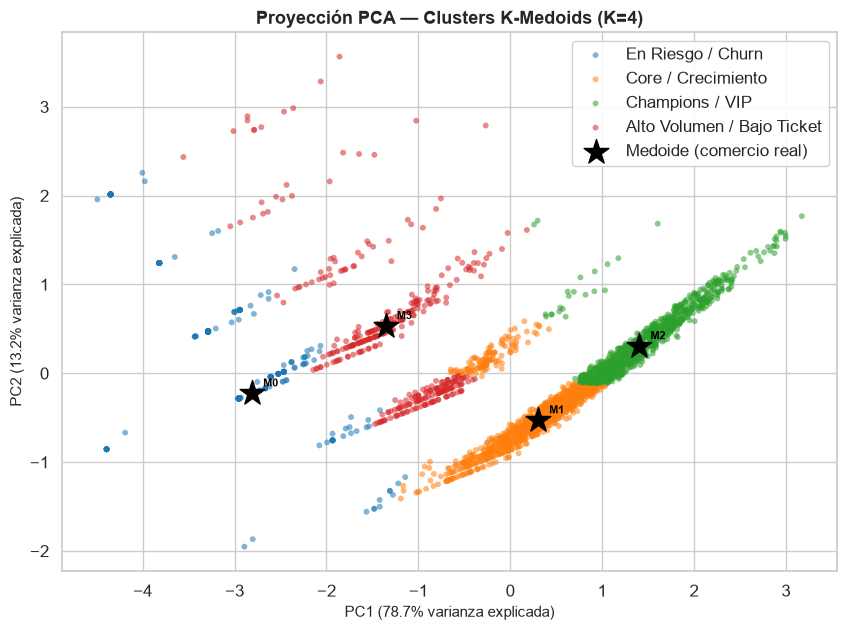


📊 Guardado: ..\data\processed\plots\kmedoids_pca_clusters.png
   Varianza total PC1+PC2: 91.9%


In [11]:
pca   = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id in sorted(df_raw["cluster"].unique()):
    mask = (df_raw["cluster"] == cluster_id).values
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=[PALETTE[cluster_id]],
        label=SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        alpha=0.55, s=18, edgecolors="none",
    )

if len(medoid_indices) > 0:
    ax.scatter(
        X_pca[medoid_indices, 0], X_pca[medoid_indices, 1],
        c="black", marker="*", s=350, zorder=5, label="Medoide (comercio real)",
    )
    for i, idx in enumerate(medoid_indices):
        ax.annotate(f"M{i}", (X_pca[idx, 0], X_pca[idx, 1]),
                    textcoords="offset points", xytext=(8, 5),
                    fontsize=8, fontweight="bold", color="black")

var_exp = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}% varianza explicada)", fontsize=11)
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}% varianza explicada)", fontsize=11)
ax.set_title("Proyecci\u00f3n PCA \u2014 Clusters K-Medoids (K=4)",
             fontsize=13, fontweight="bold")
ax.legend(loc="best", framealpha=0.9)

pca_path = PLOTS_DIR / "kmedoids_pca_clusters.png"
plt.savefig(pca_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n\U0001f4ca Guardado: {pca_path}")
print(f"   Varianza total PC1+PC2: {sum(var_exp)*100:.1f}%")

## 8b. Visualización 3D — Espacio RFM Original

Proyección 3D de los 3 015 comercios en las variables **recency_days**, **frequency** y **monetary** (escaladas) con los clusters K-Medoids (K=4) y los **medoides** (★).

> A diferencia de PCA, este gráfico usa las variables originales del espacio RFM sin compresión de dimensionalidad, lo que permite evaluar visualmente la separación de clusters en las métricas que realmente definen la segmentación.

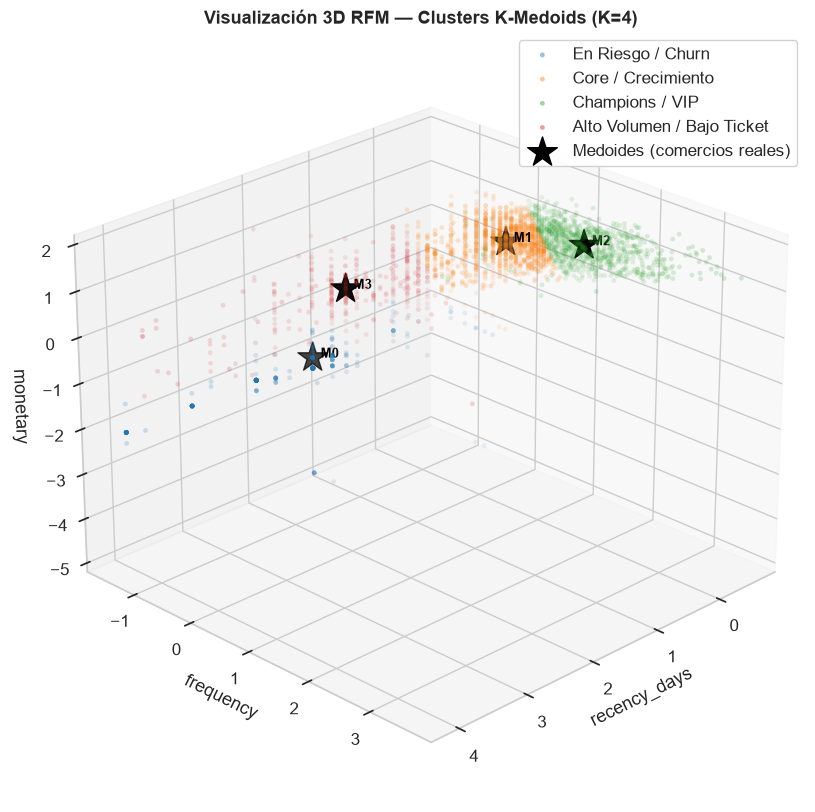

📊 Guardado: ..\data\processed\plots\kmedoids_rfm_3d.png


In [12]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for projection="3d")

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")

# Use scaled features so axes are comparable
r_col = ACTIVE_FEATURE_SET.index("recency_days")
f_col = ACTIVE_FEATURE_SET.index("frequency")
m_col = ACTIVE_FEATURE_SET.index("monetary")

for cluster_id in sorted(df_raw["cluster"].unique()):
    mask = (df_raw["cluster"] == cluster_id).values
    ax.scatter(
        X_scaled[mask, r_col],
        X_scaled[mask, f_col],
        X_scaled[mask, m_col],
        c=[PALETTE[cluster_id]],
        label=SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        alpha=0.45, s=12, edgecolors="none",
    )

# Mark medoids with stars
if len(medoid_indices) > 0:
    ax.scatter(
        X_scaled[medoid_indices, r_col],
        X_scaled[medoid_indices, f_col],
        X_scaled[medoid_indices, m_col],
        c="black", marker="*", s=500, zorder=5, label="Medoides (comercios reales)",
    )
    for i, idx in enumerate(medoid_indices):
        ax.text(
            X_scaled[idx, r_col],
            X_scaled[idx, f_col],
            X_scaled[idx, m_col],
            f"  M{i}", fontsize=9, fontweight="bold", color="black",
        )

ax.set_xlabel(ACTIVE_FEATURE_SET[0])
ax.set_ylabel(ACTIVE_FEATURE_SET[1])
ax.set_zlabel(ACTIVE_FEATURE_SET[2])
ax.set_title("Visualización 3D RFM — Clusters K-Medoids (K=4)", fontsize=13, fontweight="bold")
ax.view_init(elev=25, azim=45)
ax.legend(loc="upper right", framealpha=0.9)

save_path = PLOTS_DIR / "kmedoids_rfm_3d.png"
plt.savefig(save_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {save_path}")

## 9. Pruebas de Estabilidad — Adjusted Rand Index (ARI)

20 corridas independientes con distintas semillas. ARI calculado entre todos los pares.

| ARI Medio | Interpretación |
|-----------|---------------|
| > 0.85 | ✅ Alta estabilidad — solución robusta y reproducible |
| 0.60 – 0.85 | ⚠️ Estabilidad moderada — revisar K o preprocesamiento |
| < 0.60 | ❌ Baja estabilidad — solución inestable |

> K-Medoids suele ser más estable que K-Means en datasets con outliers,
> porque el medoide no "flota" entre corridas.

In [13]:
def evaluate_stability(X: np.ndarray, k: int, n_runs: int = 20,
                       base_seed: int = 42) -> dict:
    """Eval\u00faa la estabilidad del clustering mediante ARI entre corridas.

    Args:
        X: Array escalado de shape (n_samples, n_features).
        k: N\u00famero de clusters a evaluar.
        n_runs: N\u00famero de corridas independientes.
        base_seed: Semilla base (se incrementa por corrida).

    Returns:
        Dict con estad\u00edsticas ARI: mean, std, min, max, n_pairs.
    """
    all_labels = []
    for i in range(n_runs):
        seed         = base_seed + i * 7
        labels, _, _ = fit_kmedoids(X, k, seed)
        all_labels.append(labels)

    ari_scores = [
        adjusted_rand_score(all_labels[i], all_labels[j])
        for i in range(n_runs)
        for j in range(i + 1, n_runs)
    ]
    return {
        "ari_mean": float(np.mean(ari_scores)),
        "ari_std" : float(np.std(ari_scores)),
        "ari_min" : float(np.min(ari_scores)),
        "ari_max" : float(np.max(ari_scores)),
        "n_pairs" : len(ari_scores),
    }


print(f"\U0001f504 Ejecutando 20 corridas para estabilidad (K={K_FINAL})...")
stability = evaluate_stability(X_scaled, K_FINAL, n_runs=20, base_seed=RANDOM_STATE)

print(f"\n\u2500\u2500 Resultados de Estabilidad (ARI, {stability['n_pairs']} pares) \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500")
print(f"   ARI Medio : {stability['ari_mean']:.4f}")
print(f"   ARI Std   : {stability['ari_std']:.4f}")
print(f"   ARI M\u00edn   : {stability['ari_min']:.4f}")
print(f"   ARI M\u00e1x   : {stability['ari_max']:.4f}")

if stability["ari_mean"] > 0.85:
    print("\n\u2705 Alta estabilidad: soluci\u00f3n robusta y reproducible")
elif stability["ari_mean"] > 0.60:
    print("\n\u26a0\ufe0f  Estabilidad moderada: considerar m\u00e1s semillas o ajuste de K")
else:
    print("\n\u274c Baja estabilidad: revisar K y preprocesamiento")

🔄 Ejecutando 20 corridas para estabilidad (K=4)...



── Resultados de Estabilidad (ARI, 190 pares) ───────────────────────────────
   ARI Medio : 0.7819
   ARI Std   : 0.2219
   ARI Mín   : 0.3995
   ARI Máx   : 1.0000

⚠️  Estabilidad moderada: considerar más semillas o ajuste de K


## 10. Guardado de Metadata — Trazabilidad del Experimento

El JSON documenta todas las decisiones metodológicas para reproducibilidad y auditoría:
- Timestamp de ejecución y backend usado
- Dataset fuente y features seleccionadas
- Configuración de preprocesamiento
- Parámetros del modelo y métricas finales
- Resultados de estabilidad ARI
- IDs de los comercios medoides representativos

In [14]:
metadata = {
    "experiment": {
        "timestamp" : datetime.now().isoformat(),
        "notebook"  : "segmentation_evaluation_k_medoids.ipynb",
        "suffix"    : SUFFIX,
        "backend"   : KMEDOIDS_BACKEND,
    },
    "data": {
        "source"            : "comercios_segmented_prep.csv",
        "n_comercios"       : int(len(df_raw)),
        "n_features_set_a"  : len(FEATURE_SET_A),
        "n_features_set_b"  : len(FEATURE_SET_B),
        "active_feature_set": "A" if ACTIVE_FEATURE_SET == FEATURE_SET_A else "B",
        "features_used"     : ACTIVE_FEATURE_SET,
    },
    "preprocessing": {
        "log_transform"               : LOG_TRANSFORM,
        "log_transform_applied_to"    : ["monetary", "frequency"],
        "log_transform_not_applied_to": ["recency_days"],
        "scaler"                      : SCALE_METHOD,
        "skew_threshold"              : SKEW_THRESHOLD,
        "outliers_top_01pct"          : "mantenidos_en_muestra",
    },
    "model": {
        "algorithm"           : "K-Medoids (PAM)",
        "k_evaluated"         : list(K_RANGE),
        "k_selected"          : K_FINAL,
        "k2_discarded_reason" : "solucion_trivial_no_accionable",
        "metric"              : "euclidean",
        "method"              : "pam",
        "random_state"        : RANDOM_STATE,
        "silhouette_final"    : round(sil_final, 4),
        "davies_bouldin_final": round(db_final, 4),
        "cost_final"          : round(cost_final, 2),
    },
    "stability": {
        "n_runs"  : 20,
        "ari_mean": round(stability["ari_mean"], 4),
        "ari_std" : round(stability["ari_std"], 4),
        "ari_min" : round(stability["ari_min"], 4),
        "ari_max" : round(stability["ari_max"], 4),
    },
    "outputs": {
        "model"        : str(model_path),
        "scaler"       : str(scaler_path),
        "dataset_final": str(final_csv_path),
        "perfiles"     : str(profiles_csv_path),
    },
    "segments": SEGMENT_NAMES,
    "medoids" : {str(i): str(mid) for i, mid in enumerate(medoid_ids)},
}

metadata_path = DATA_DIR / f"metadata_segmentation{SUFFIX}.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"\U0001f4be Metadata guardada: {metadata_path}")
print(f"   Timestamp: {metadata['experiment']['timestamp']}")
print(f"   Backend  : {metadata['experiment']['backend']}")
print(f"   K Final  : {metadata['model']['k_selected']}")
print(f"   Sil Final: {metadata['model']['silhouette_final']}")

💾 Metadata guardada: ..\data\processed\metadata_segmentation_k_medoids.json
   Timestamp: 2026-07-25T17:24:52.151405
   Backend  : pyclustering
   K Final  : 4
   Sil Final: 0.4185


### Segmento 0 — Champions / VIP
**Perfil**: Alta recencia (días sin transaccionar), baja frecuencia reciente

**Estrategia**:
- 🚨 Alerta temprana de churn → intervención proactiva del equipo comercial en D+14
- 💰 Descuento temporal del 30% en comisión por 60 días de reactivación
- 📞 Llamada de diagnóstico para identificar fricción en el proceso de cobro

---

### Segmento 1 — Core / Crecimiento
**Perfil**: Frecuencia y monetary medios, actividad regular, potencial de expansión

**Estrategia**:
- 📈 Campaña de cross-selling hacia terminales adicionales (incentivo por 2.ª terminal)
- 🎯 Bonificaciones escalonadas por incremento de ticket promedio
- 📱 Onboarding guiado en funciones avanzadas de la plataforma de pagos

---

### Segmento 0 — En Riesgo / Churn
**Perfil**: Alta frecuencia, alto monetary, baja recencia (activos recientemente)

**Estrategia**:
- 🏆 Programa de fidelización premium con tasas de comisión preferencial
- 📊 Reportes mensuales personalizados de rendimiento vs. benchmark del sector
- 🤝 Asesor comercial dedicado y acceso anticipado a nuevas funcionalidades API

---

### Segmento 3 — Alto Volumen / Bajo Ticket
**Perfil**: Muchas transacciones, ticket promedio bajo (micro-pagos recurrentes)

**Estrategia**:
- 📦 Paquetes de volumen con tasa reducida por transacción (>500 tx/mes)
- 🔄 Integración con soluciones de cobro recurrente (suscripciones y membresías)
- 🏷️ Análisis de subcategoría para identificar verticales con potencial de upselling

---

### Proyección de Impacto
- **+50% en comisiones** concentrando esfuerzo comercial en Champions y Core
- **Reducción de churn del 30%** mediante intervención temprana en Segmento 0
- **Eficiencia de marketing**: presupuesto asignado según rentabilidad real de cada segmento

In [15]:
print("\u2550\u2550\u2550 Verificaci\u00f3n Final de Artefactos \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
outputs = [
    final_csv_path,
    profiles_csv_path,
    metadata_path,
    model_path,
    scaler_path,
    PLOTS_DIR / "kmedoids_elbow_comparison.png",
    PLOTS_DIR / "kmedoids_silhouette_comparison.png",
    PLOTS_DIR / "kmedoids_davies_bouldin.png",
    PLOTS_DIR / "kmedoids_silhouette_samples.png",
    PLOTS_DIR / "kmedoids_pca_clusters.png",
    PLOTS_DIR / "kmedoids_rfm_3d.png",
    PLOTS_DIR / "kmedoids_correlation_matrix.png",
    PLOTS_DIR / "kmedoids_distributions_raw.png",
    PLOTS_DIR / "kmedoids_cluster_profiles.png",
]
all_ok = True
for p in outputs:
    exists = Path(p).exists()
    status = "\u2705" if exists else "\u274c FALTANTE"
    if not exists:
        all_ok = False
    print(f"   {status}  {p}")

print()
if all_ok:
    print("\u2705 Todos los artefactos generados correctamente.")
else:
    print("\u26a0\ufe0f  Algunos artefactos faltan. Revisa las celdas anteriores.")

print("\n\u2550\u2550\u2550 Resumen Ejecutivo \u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550\u2550")
print(f"   Algoritmo  : K-Medoids (PAM) \u2014 backend: {KMEDOIDS_BACKEND}")
print(f"   K Final    : {K_FINAL} clusters")
print(f"   Features   : {ACTIVE_FEATURE_SET}")
print(f"   Scaler     : {SCALE_METHOD}")
print(f"   Sil Score  : {sil_final:.4f}")
print(f"   Davies-Boul: {db_final:.4f}")
print(f"   ARI Medio  : {stability['ari_mean']:.4f} (estabilidad)")
print(f"   Comercios  : {len(df_raw):,}")

═══ Verificación Final de Artefactos ═══════════════════════════════════════════════════════════
   ✅  ..\data\processed\comercios_final_k_medoids.csv
   ✅  ..\data\processed\perfiles_segmentos_k_medoids.csv
   ✅  ..\data\processed\metadata_segmentation_k_medoids.json
   ✅  ..\data\processed\model_k_medoids.pkl
   ✅  ..\data\processed\scaler_k_medoids.pkl
   ✅  ..\data\processed\plots\kmedoids_elbow_comparison.png
   ✅  ..\data\processed\plots\kmedoids_silhouette_comparison.png
   ✅  ..\data\processed\plots\kmedoids_davies_bouldin.png
   ✅  ..\data\processed\plots\kmedoids_silhouette_samples.png
   ✅  ..\data\processed\plots\kmedoids_pca_clusters.png
   ✅  ..\data\processed\plots\kmedoids_rfm_3d.png
   ✅  ..\data\processed\plots\kmedoids_correlation_matrix.png
   ✅  ..\data\processed\plots\kmedoids_distributions_raw.png
   ✅  ..\data\processed\plots\kmedoids_cluster_profiles.png

✅ Todos los artefactos generados correctamente.

═══ Resumen Ejecutivo ════════════════════════════════════